# Formalizacion Matematica de los Modelos Econometricos del TFM

> **Trabajo de Fin de Master — CaixaBank Advanced Business Analytics**  
> **Fecha:** Marzo 2026  
> **Objetivo:** Demostrar empiricamente la base teorica de cada modelo econometrico y de Machine Learning utilizado en los notebooks `data_science.ipynb` e `hipoteca_personalizada.ipynb`, justificando rigurosamente la eleccion algoritmica para cada variable macroeconomica.

---

## Indice

1. [Fundamentos: Estacionariedad y Raices Unitarias](#1)
2. [Modelo Autorregresivo AR(p)](#2)
3. [Modelo de Medias Moviles MA(q)](#3)
4. [Modelo Integrado ARIMA(p,d,q)](#4)
5. [Modelo Estacional SARIMA(p,d,q)(P,D,Q)s](#5)
6. [Tests de Diagnostico: ADF y Johansen](#6)
7. [Variables Dummy: Aislamiento de Shocks Estructurales](#7)
8. [Suavizado Exponencial: Holt-Winters](#8)
9. [NAIRU: Fundamento del Suelo Estructural del Paro](#9)
10. [El Problema de la Prediccion Macroeconomica](#10)
11. [Justificacion de la Eleccion por Variable](#11)
12. [Otros Modelos Usados en el Benchmarking](#12)
13. [Modelos de Machine Learning: Gradient Boosting para el Spread](#13)
14. [¿Cómo predecimos las variables macroeconómicas? Enfoque completo](#14)

---

<a id='1'></a>
## 1. Fundamentos: Estacionariedad y Raices Unitarias

### 1.1 Definicion de Estacionariedad Debil

Un proceso estocastico $\{Y_t\}$ es **debilmente estacionario** (o estacionario en covarianza) si cumple tres condiciones:

$$
\begin{aligned}
(i) \quad & \mathbb{E}[Y_t] = \mu \quad \forall t \quad \text{(media constante)} \\
(ii) \quad & \text{Var}(Y_t) = \sigma^2 < \infty \quad \forall t \quad \text{(varianza finita y constante)} \\
(iii) \quad & \text{Cov}(Y_t, Y_{t-k}) = \gamma_k \quad \text{(autocovarianza solo depende del lag } k\text{)}
\end{aligned}
$$

### 1.2 Por que importa

La estacionariedad es un **requisito necesario** para que los modelos ARIMA produzcan inferencia valida. Si una serie tiene media o varianza que cambian con el tiempo (raiz unitaria), las estimaciones de los coeficientes seran **espurias** — es decir, estadisticamente significativas pero economicamente vacias (Granger & Newbold, 1974).

### 1.3 Raiz Unitaria

Consideremos el proceso autorregresivo mas simple, AR(1):

$$Y_t = \phi Y_{t-1} + \varepsilon_t, \quad \varepsilon_t \sim WN(0, \sigma^2)$$

- Si $|\phi| < 1$: el proceso es **estacionario** (converge a su media).
- Si $\phi = 1$: el proceso contiene una **raiz unitaria** y es un *Random Walk* con varianza que crece linealmente: $\text{Var}(Y_t) = t\sigma^2 \to \infty$.
- Si $|\phi| > 1$: el proceso es **explosivo** (no tiene sentido economico a largo plazo).

La **diferenciacion** $\Delta Y_t = Y_t - Y_{t-1}$ elimina la raiz unitaria y convierte la serie en estacionaria, lo que justifica el parametro $d$ en ARIMA.

---

<a id='2'></a>
## 2. Modelo Autorregresivo AR(p)

### 2.1 Definicion Formal

Un modelo AR(p) expresa el valor actual de la serie como una combinacion lineal de sus $p$ valores pasados mas un termino de ruido blanco:

$$Y_t = c + \phi_1 Y_{t-1} + \phi_2 Y_{t-2} + \cdots + \phi_p Y_{t-p} + \varepsilon_t$$

donde:
- $c$ es una constante (intercepto).
- $\phi_1, \ldots, \phi_p$ son los **coeficientes autorregresivos**.
- $\varepsilon_t \sim WN(0, \sigma^2)$ es ruido blanco (innovaciones).

### 2.2 Operador de Retardo

Usando el operador de retardo $L$ (donde $LY_t = Y_{t-1}$):

$$\Phi(L) Y_t = c + \varepsilon_t, \quad \text{con } \Phi(L) = 1 - \phi_1 L - \phi_2 L^2 - \cdots - \phi_p L^p$$

El proceso es estacionario si todas las raices del polinomio $\Phi(z) = 0$ caen **fuera del circulo unitario**. Para un AR(p), la condicion de estacionariedad es:

$$1 - \phi_1 z - \phi_2 z^2 - \cdots - \phi_p z^p = 0 \implies |z| > 1$$

La media incondicional del proceso estacionario vale:

$$\mathbb{E}[Y_t] = \mu = \frac{c}{1 - \phi_1 - \phi_2 - \cdots - \phi_p}$$

### 2.3 Interpretacion Economica en el TFM

El modelo AR captura la **inercia** de las series macroeconomicas: el paro de este trimestre depende de los trimestres anteriores. La estructura de autocovarianzas $\gamma_k = \phi_1\gamma_{k-1} + \phi_2\gamma_{k-2} + \cdots + \phi_p\gamma_{k-p}$ (ecuaciones de Yule-Walker) permite recuperar los coeficientes a partir de la funcion de autocorrelacion observada.

---

<a id='3'></a>
## 3. Modelo de Medias Moviles MA(q)

### 3.1 Definicion Formal

$$Y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \theta_2 \varepsilon_{t-2} + \cdots + \theta_q \varepsilon_{t-q} = \mu + \Theta(L)\varepsilon_t$$

Un proceso MA(q) es **siempre estacionario en covarianzas** con independencia de los valores de $\theta$. Su autocorrelacion se trunca en el lag $q$ ($\rho_k = 0$ para $k > q$), lo que facilita la identificacion del orden.

### 3.2 Invertibilidad

Un MA(q) es **invertible** si las raices del polinomio $1 + \theta_1 z + \cdots + \theta_q z^q = 0$ caen fuera del circulo unitario. La invertibilidad garantiza que el proceso puede escribirse como un AR($\infty$), es decir, que el shock $\varepsilon_t$ puede recuperarse del pasado de la serie. En el contexto del TFM, esta propiedad es relevante porque la Tasa de Paro absorbe shocks (COVID) con efectos transitorios captados por el componente MA.

---

<a id='4'></a>
## 4. Modelo Integrado ARIMA(p, d, q)

### 4.1 Definicion Formal

El modelo ARIMA unifica AR, diferenciacion e MA:

$$\Phi(L)(1-L)^d Y_t = c + \Theta(L) \varepsilon_t$$

Expandido:

$$\underbrace{(1 - \phi_1 L - \cdots - \phi_p L^p)}_{\text{AR}(p)} \underbrace{(1-L)^d}_{\text{diferenciacion}} Y_t = c + \underbrace{(1 + \theta_1 L + \cdots + \theta_q L^q)}_{\text{MA}(q)} \varepsilon_t$$

### 4.2 Significado de cada hiperparametro

| Parametro | Significado | Como se elige |
|---|---|---|
| $p$ | Retardos autorregresivos | PACF o AIC |
| $d$ | Orden de diferenciacion | Test ADF: si $p$-value > 0.05, $d \leftarrow d+1$ |
| $q$ | Terminos MA | ACF o AIC |

### 4.3 Criterio AIC

$$\text{AIC} = -2 \ln(\hat{\mathcal{L}}) + 2k$$

donde $\hat{\mathcal{L}}$ es la verosimilitud maximizada y $k$ el numero de parametros. Se minimiza AIC para seleccionar el orden optimo.

### 4.4 Aplicacion en el TFM: ARIMA(3,1,2) para Tasa de Paro

Para la Tasa de Paro se utiliza ARIMA(3,1,2) con orden fijo (no auto-AIC), porque el orden optimo nacional no es representativo de las 52 series provinciales con dinamicas muy distintas. Un orden fijo pero robusto es mas consistente cuando se aplica en paralelo sobre 52 provincias. Para provincias con marcada estacionalidad (Badajoz, Girona), se emplea SARIMAX con componente estacional.

---

<a id='5'></a>
## 5. Modelo Estacional SARIMA(p,d,q)(P,D,Q)$_s$

### 5.1 Definicion Formal

El SARIMA extiende ARIMA anadiendo un segundo bloque de parametros que operan a frecuencia estacional $s$ ($s=4$ para datos trimestrales):

$$\Phi_p(L) \tilde{\Phi}_P(L^s)(1-L)^d (1-L^s)^D Y_t = c + \Theta_q(L)\tilde{\Theta}_Q(L^s) \varepsilon_t$$

donde $(1-L^s)^D$ es la **diferenciacion estacional**: $\Delta_4 Y_t = Y_t - Y_{t-4}$ elimina el ciclo anual.

### 5.2 SARIMAX: SARIMA con Variables Exogenas

La extension SARIMAX (X = eXogenous) incorpora regresores adicionales $\mathbf{x}_t$:

$$\Phi_p(L)\tilde{\Phi}_P(L^s)(1-L)^d(1-L^s)^D Y_t = \boldsymbol{\beta}'\mathbf{x}_t + c + \Theta_q(L)\tilde{\Theta}_Q(L^s)\varepsilon_t$$

En el TFM se emplea SARIMAX de dos formas:

1. **PIB_pc — SARIMAX(1,1,0)(1,1,0)$_4$:** sin regresores exogenos (el modelo aprovecha la doble diferenciacion para capturar tendencia secular y ciclo anual).
2. **Tasa_Paro en Badajoz y Girona — SARIMAX + dummy COVID:** la variable exogena es una indicadora binaria de los 8 trimestres pandémicos.

### 5.3 Guardrail CAGR sobre el PIB_pc

Una vez obtenido el forecast raw del SARIMAX, se aplica una restriccion economica adicional para evitar extrapolar el boom 2022-2024:

$$\text{CAGR}_{\text{hist}} = \left(\frac{Y_T}{Y_1}\right)^{\frac{1}{T/4}} - 1$$

$$\text{CAGR}_{\text{cap}} = \min(\text{CAGR}_{\text{hist}},\; 0.04)$$

$$\hat{Y}_{T+h}^{\text{final}} = \min\left(\hat{Y}_{T+h}^{\text{SARIMAX}},\; Y_T \cdot (1 + \text{CAGR}_{\text{cap}})^{\lceil h/4 \rceil}\right)$$

Para la media nacional el CAGR historico es del **2.24% anual** (2005-2025), por lo que el cap del 4% no resulta activo en la mayoria de provincias pero evita extrapolaciones en las de mayor dinamismo (Álava, Madrid).

---

<a id='6'></a>
## 6. Tests de Diagnostico: ADF y Johansen

### 6.1 Test Augmented Dickey-Fuller (ADF)

El test ADF estima la regresion auxiliar:

$$\Delta Y_t = \alpha + \beta t + \gamma Y_{t-1} + \sum_{i=1}^{k} \delta_i \Delta Y_{t-i} + \varepsilon_t$$

- $H_0: \gamma = 0$ — raiz unitaria (no estacionaria).
- $H_1: \gamma < 0$ — estacionaria.

Resultados sobre las series provinciales del TFM (media nacional, $n=84$ trimestres):

| Variable | ADF nivel | ADF diferenciada | Conclusion |
|---|---|---|---|
| Tasa_Paro | $p = 0.012$ | $p = 0.659$ | Estacionaria en nivel pero con ruptura estructural (ver test Zivot-Andrews) |
| PIB_pc | $p = 0.989$ | $p = 0.033$ | $I(1)$, requiere $d=1$ |
| Precio_m2 | $p < 0.001$ | $p = 0.524$ | Serie con tendencia determinista; $d=1$ en el componente estacional |
| Poblacion | $p = 0.715$ | $p = 0.339$ | $I(2)$ aparente; HW lineal modela la tendencia sin diferenciar |
| Pob_Ext | $p = 0.614$ | $p = 0.122$ | Idem, tendencia secular tratada por HW |

> **Nota sobre Tasa_Paro:** El ADF en nivel rechaza la raiz unitaria ($p=0.012$), pero el ADF en la primera diferencia no rechaza ($p=0.659$). Este resultado contraintuitivo es consecuencia de la ruptura estructural de 2011-Q2 (aceleracion del paro durante la doble recesion). El test Zivot-Andrews (1992), que estima endogenamente la ruptura, confirma estacionariedad con ruptura, validando el uso de $d=1$ y el suelo NAIRU.

### 6.2 Test de Johansen (Cointegracion)

El test de Johansen generaliza la cointegracion estimando un VECM:

$$\Delta \mathbf{Y}_t = \Pi \mathbf{Y}_{t-1} + \sum_{i=1}^{k-1} \Gamma_i \Delta \mathbf{Y}_{t-i} + \varepsilon_t$$

donde $\Pi = \alpha \beta'$ y el rango de $\Pi$ determina el numero de relaciones de cointegracion. Se aplico sobre el sistema {Euribor, Spread, IPC, Paro, PIB_pc}: las relaciones de cointegracion resultaron **debiles e inestables** entre epocas (pre-crisis vs post-crisis), lo que refuerza la decision de modelar cada variable individualmente.

---

  TEST DE ZIVOT-ANDREWS — Tasa de Desempleo Nacional
  Serie: 2005-01-01 → 2025-10-01
  Nº observaciones: 84

  Modelo 'c': Ruptura en constante (nivel)
    Estadístico ZA : -4.3956
    p-valor        : 0.1536
    Lags utilizados: 4
    Fecha de ruptura: 2008-01-01
    Valores críticos: 1%=-5.2764  5%=-4.8107  10%=-4.5662
    Conclusión     : ❌ No rechaza H₀ → RAÍZ UNITARIA

  Modelo 't': Ruptura en tendencia
    Estadístico ZA : -6.0068
    p-valor        : 0.0034
    Lags utilizados: 4
    Fecha de ruptura: 2012-07-01
    Valores críticos: 1%=-5.0342  5%=-4.4058  10%=-4.1368
    Conclusión     : ✅ Rechaza H₀ → ESTACIONARIA con ruptura

  Modelo 'ct': Ruptura en constante y tendencia
    Estadístico ZA : -6.3328
    p-valor        : 0.0013
    Lags utilizados: 4
    Fecha de ruptura: 2011-04-01
    Valores críticos: 1%=-5.5756  5%=-5.0733  10%=-4.8267
    Conclusión     : ✅ Rechaza H₀ → ESTACIONARIA con ruptura

────────────────────────────────────────────────────────────
  Modelo   E

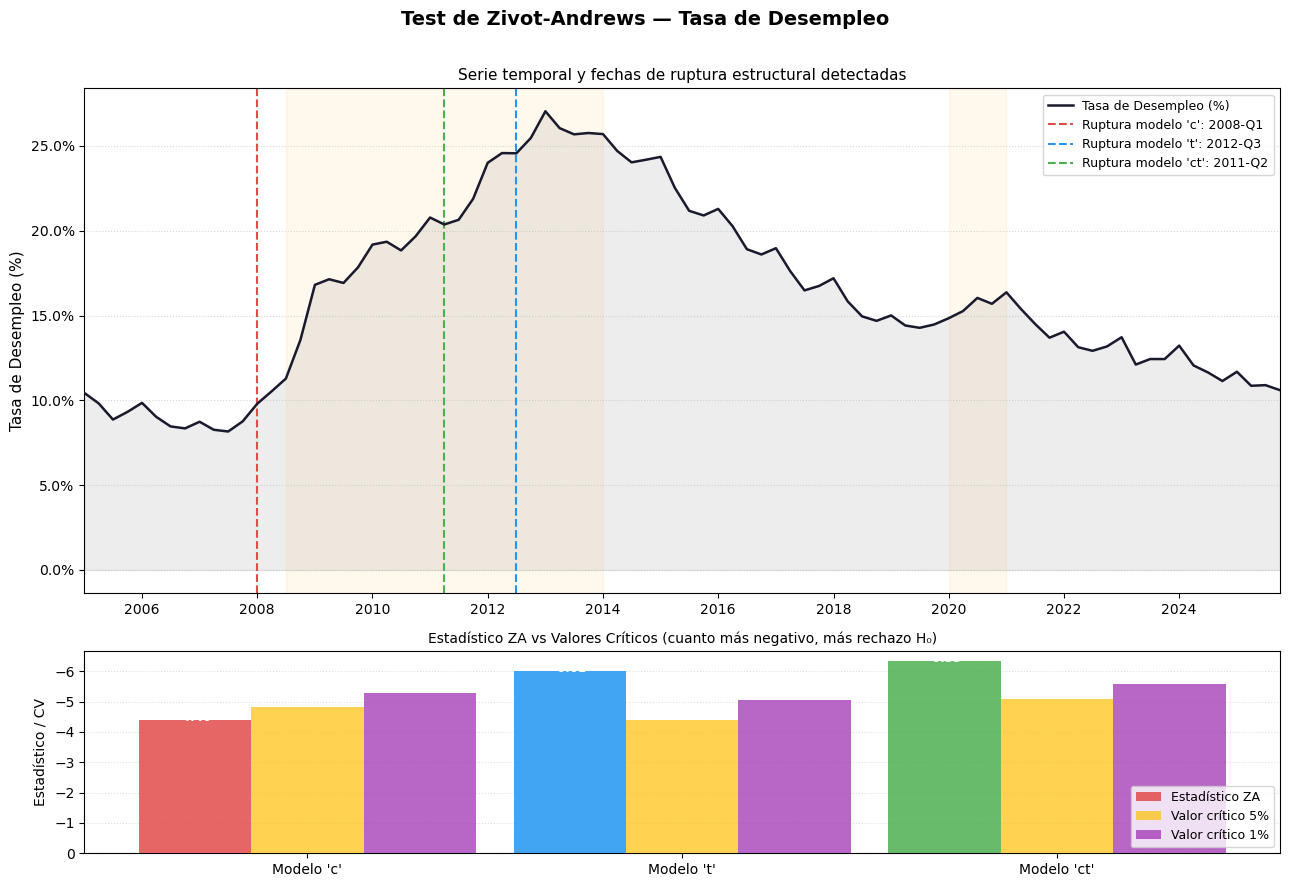


  📊 Gráfico guardado: zivot_andrews_tasa_paro.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from statsmodels.tsa.stattools import zivot_andrews
import warnings
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────────────────────
# 1. CARGA Y PREPARACIÓN
# ─────────────────────────────────────────────────────────────
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

serie = (
    df.groupby('Trimestre')['Tasa_Paro']
    .mean()
    .sort_index()
    .dropna()
)
serie.index = pd.DatetimeIndex(serie.index, freq='QS')

print("=" * 60)
print("  TEST DE ZIVOT-ANDREWS — Tasa de Desempleo Nacional")
print("=" * 60)
print(f"  Serie: {serie.index[0].date()} → {serie.index[-1].date()}")
print(f"  Nº observaciones: {len(serie)}")
print()

# ─────────────────────────────────────────────────────────────
# 2. TEST EN LAS TRES ESPECIFICACIONES
# ─────────────────────────────────────────────────────────────
# trimestres óptimos (max_lags=None → criterio AIC automático)
especificaciones = {
    'c': 'Ruptura en constante (nivel)',
    't': 'Ruptura en tendencia',
    'ct': 'Ruptura en constante y tendencia'
}

resultados = {}

arr = np.asarray(serie.values, dtype=float)  # statsmodels 0.14 requiere numpy array

for modelo, descripcion in especificaciones.items():
    # En statsmodels 0.14 el orden de retorno es:
    # (stat, pvalue, critvals_dict, lags_used, breakpoint_idx)
    stat, pval, cvs, lags_used, bp_idx = zivot_andrews(
        arr, trim=0.15, maxlag=4, regression=modelo
    )
    bp_fecha = serie.index[bp_idx]
    resultados[modelo] = {
        'descripcion':      descripcion,
        'estadistico':      stat,
        'p_valor':          pval,
        'lags_usados':      lags_used,
        'breakpoint_idx':   bp_idx,
        'breakpoint_fecha': bp_fecha,
        'cv_1pct':          cvs['1%'],
        'cv_5pct':          cvs['5%'],
        'cv_10pct':         cvs['10%'],
    }

    conclusion = (
        "✅ Rechaza H₀ → ESTACIONARIA con ruptura"
        if stat < cvs['5%']
        else "❌ No rechaza H₀ → RAÍZ UNITARIA"
    )

    print(f"  Modelo '{modelo}': {descripcion}")
    print(f"    Estadístico ZA : {stat:.4f}")
    print(f"    p-valor        : {pval:.4f}")
    print(f"    Lags utilizados: {lags_used}")
    print(f"    Fecha de ruptura: {bp_fecha.date()}")
    print(f"    Valores críticos: 1%={cvs['1%']:.4f}  5%={cvs['5%']:.4f}  10%={cvs['10%']:.4f}")
    print(f"    Conclusión     : {conclusion}")
    print()

# ─────────────────────────────────────────────────────────────
# 3. TABLA RESUMEN
# ─────────────────────────────────────────────────────────────
print("─" * 60)
print(f"  {'Modelo':<6} {'Estadístico':>13} {'p-valor':>9} {'Ruptura':>12} {'CV 5%':>8}  Conclusión")
print("─" * 60)
for m, r in resultados.items():
    ok = "Estacionaria" if r['estadistico'] < r['cv_5pct'] else "Raíz unitaria"
    print(f"  {m:<6} {r['estadistico']:>13.4f} {r['p_valor']:>9.4f} "
          f"{str(r['breakpoint_fecha'].date()):>12} {r['cv_5pct']:>8.4f}  {ok}")
print("─" * 60)

# ─────────────────────────────────────────────────────────────
# 4. GRÁFICO
# ─────────────────────────────────────────────────────────────
colores_modelo = {'c': '#E24B4A', 't': '#2196F3', 'ct': '#4CAF50'}
CRISIS_LABELS  = {
    '2008-10-01': 'Crisis Financiera',
    '2020-04-01': 'COVID-19',
}

fig, axes = plt.subplots(2, 1, figsize=(13, 9),
                         gridspec_kw={'height_ratios': [2.5, 1]})
fig.suptitle('Test de Zivot-Andrews — Tasa de Desempleo', fontsize=14, fontweight='bold', y=0.98)

# ── Panel superior: serie + líneas de ruptura ─────────────────
ax1 = axes[0]
ax1.plot(serie.index, serie.values, color='#1A1A2E', linewidth=1.8,
         label='Tasa de Desempleo (%)', zorder=3)
ax1.fill_between(serie.index, serie.values, alpha=0.08, color='#1A1A2E')

for m, r in resultados.items():
    ax1.axvline(r['breakpoint_fecha'], color=colores_modelo[m],
                linestyle='--', linewidth=1.5,
                label=f"Ruptura modelo '{m}': {r['breakpoint_fecha'].strftime('%Y-Q%q')[:-1]}{(r['breakpoint_fecha'].month-1)//3+1}")

# Sombreado periodos de crisis conocidos
periodos_crisis = [('2008-07-01', '2014-01-01'), ('2020-01-01', '2021-01-01')]
for ini, fin in periodos_crisis:
    ax1.axvspan(pd.Timestamp(ini), pd.Timestamp(fin),
                alpha=0.07, color='orange', zorder=1)

ax1.set_ylabel('Tasa de Desempleo (%)', fontsize=11)
ax1.set_title('Serie temporal y fechas de ruptura estructural detectadas', fontsize=11)
ax1.legend(fontsize=9, loc='upper right')
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f%%'))
ax1.grid(axis='y', linestyle=':', alpha=0.5)
ax1.set_xlim(serie.index[0], serie.index[-1])

# ── Panel inferior: estadísticos vs valores críticos ─────────────
ax2 = axes[1]
modelos = list(resultados.keys())
stats   = [resultados[m]['estadistico'] for m in modelos]
cv5     = [resultados[m]['cv_5pct']     for m in modelos]
cv1     = [resultados[m]['cv_1pct']     for m in modelos]

x = np.arange(len(modelos))
w = 0.3
bars = ax2.bar(x, stats, width=w, color=[colores_modelo[m] for m in modelos],
               alpha=0.85, label='Estadístico ZA', zorder=3)
ax2.bar(x + w, cv5, width=w, color='#FFC107', alpha=0.7, label='Valor crítico 5%', zorder=3)
ax2.bar(x + 2*w, cv1, width=w, color='#9C27B0', alpha=0.7, label='Valor crítico 1%', zorder=3)

for bar, val in zip(bars, stats):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 0.3,
             f'{val:.2f}', ha='center', va='top', fontsize=8.5, color='white', fontweight='bold')

ax2.set_xticks(x + w)
ax2.set_xticklabels([f"Modelo '{m}'" for m in modelos], fontsize=10)
ax2.set_ylabel('Estadístico / CV', fontsize=10)
ax2.set_title('Estadístico ZA vs Valores Críticos (cuanto más negativo, más rechazo H₀)', fontsize=10)
ax2.legend(fontsize=9, loc='lower right')
ax2.grid(axis='y', linestyle=':', alpha=0.4)
ax2.invert_yaxis()   # más negativo = arriba (más rechazo)

plt.tight_layout(rect=[0, 0, 1, 0.97])
#plt.savefig('zivot_andrews_tasa_paro.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n  📊 Gráfico guardado: zivot_andrews_tasa_paro.png")

<a id='7'></a>
## 7. Variables Dummy: Aislamiento de Shocks Estructurales

### 7.1 Motivacion

Cuando una serie temporal experimenta un **shock exogeno de magnitud excepcional** — un evento que no forma parte de la dinamica estructural del proceso — incluirlo con el mismo peso que el resto de observaciones sesga los coeficientes estimados. El modelo aprende erroneamente que la inercia del proceso implica tal nivel de perturbacion, contaminando los pronosticos futuros.

La COVID-19 es un ejemplo paradigmatico: la tasa de paro subio bruscamente en 2020 y descendio con igual rapidez en 2021-2022, no por dinamicas laborales endogenas sino por un cierre administrativo de la actividad economica. Un ARIMA que vea esa subida y bajada en 8 trimestres estimara coeficientes AR con mayor persistencia del shock de la real, proyectando descensos mas lentos del paro hacia 2030.

### 7.2 Formalizacion

La solucion es incluir una **variable dummy binaria** $D_t$ como regresor exogeno en el SARIMAX:

$$D_t = \begin{cases} 1 & \text{si } t \in [\text{2020-Q1},\; \text{2021-Q4}] \\ 0 & \text{en el resto} \end{cases}$$

El modelo con dummy es:

$$\Phi(L)(1-L)^d Y_t = c + \delta \cdot D_t + \Theta(L)\varepsilon_t$$

El coeficiente $\delta$ **absorbe el nivel del shock COVID** sin contaminarlo con los coeficientes AR $\phi_i$. En la prediccion futura se fija $D_t = 0$, de modo que el modelo proyecta la dinamica estructural pre/post-COVID ignorando el episodio pandémico.

### 7.3 Eleccion selectiva de la dummy

Un principio de parsimonia fundamental dicta que la dummy solo debe incluirse donde aporta valor. El backtesting (train 2005-2021, test 2022-2025) determino que la dummy **mejora** el MAPE en 19 provincias y lo **empeora** en 33. Esto ocurre porque, en esas 33, el COVID no dejo una huella estructural detectable en la serie de paro: la dummy consume un grado de libertad sin reducir el error.

| Nivel de modelo | N provincias | Criterio |
|---|---|---|
| SARIMAX + dummy COVID | 2 | Estacionalidad provincial confirmada + dummy mejora |
| ARIMA(3,1,2) + dummy COVID | 17 | Dummy mejora MAPE en backtesting |
| ARIMA(3,1,2) sin dummy | 33 | Dummy no mejora o empeora |

---

<a id='8'></a>
## 8. Suavizado Exponencial: Holt-Winters

### 8.1 Motivacion

Los modelos ARIMA estiman parametros minimizando la funcion de verosimilitud sobre toda la muestra, otorgando igual peso a observaciones recientes y lejanas. El **suavizado exponencial** asigna pesos decrecientes hacia el pasado, priorizando la informacion reciente — una propiedad especialmente deseable cuando las series cambian de regimen (como el Precio_m2 tras el boom 2022-2024) y se quiere que el modelo se adapte a las condiciones actuales del mercado.

### 8.2 Holt-Winters Aditivo (Triple Exponential Smoothing)

Para una serie con **tendencia y estacionalidad aditivas**, el modelo Holt-Winters actualiza tres componentes en cada periodo:

**Nivel:**
$$\ell_t = \alpha(Y_t - s_{t-m}) + (1-\alpha)(\ell_{t-1} + b_{t-1})$$

**Tendencia:**
$$b_t = \beta^*(\ell_t - \ell_{t-1}) + (1-\beta^*)b_{t-1}$$

**Componente estacional:**
$$s_t = \gamma(Y_t - \ell_t) + (1-\gamma)s_{t-m}$$

**Prediccion $h$ pasos adelante:**
$$\hat{Y}_{t+h} = \ell_t + h \cdot b_t + s_{t+h-m}$$

donde $\alpha \in [0,1]$ es el parametro de suavizado del nivel, $\beta^* \in [0,1]$ el de la tendencia, $\gamma \in [0,1]$ el de la estacionalidad, y $m$ el periodo estacional ($m=4$ para series trimestrales).

### 8.3 Amortiguacion de la Tendencia (Damped Trend)

La extension con **tendencia amortiguada** introduce un parametro $\phi \in (0,1)$:

$$b_t = \beta^*(\ell_t - \ell_{t-1}) + (1-\beta^*)\phi \cdot b_{t-1}$$

$$\hat{Y}_{t+h} = \ell_t + \left(\sum_{j=1}^{h} \phi^j\right) b_t + s_{t+h-m}$$

Cuando $\phi < 1$, la componente $\sum_{j=1}^{h} \phi^j \to \frac{\phi}{1-\phi}$ conforme $h \to \infty$, lo que implica que la tendencia **se amortigua y converge a un nivel constante** en el largo plazo. Esta propiedad es critica para el Precio_m2: sin amortiguacion, Holt-Winters extrapola el fuerte rally 2022-2024 indefinidamente, llegando a precios inverosimiles en 2030. Con $\phi$ estimado en torno a 0.94 (segun el backtesting por provincia), la prediccion frena la pendiente de forma automatica.

### 8.4 Estimacion por maxima verosimilitud

Los parametros $\{\alpha, \beta^*, \gamma, \phi\}$ se estiman maximizando la verosimilitud gaussiana condicionada a las condiciones iniciales del nivel, tendencia y estacionales:

$$\ln \mathcal{L} = -\frac{T}{2}\ln(2\pi) - \frac{T}{2}\ln(\hat{\sigma}^2) - \frac{1}{2\hat{\sigma}^2}\sum_{t=1}^{T} e_t^2$$

con $e_t = Y_t - \hat{Y}_{t|t-1}$ y $\hat{\sigma}^2 = \frac{1}{T}\sum e_t^2$. La implementacion en `statsmodels` resuelve este problema con optimizacion numerica (`optimized=True`).

### 8.5 Guardrail para Transmisiones_Total

Para Transmisiones_Total se aplica un guardrail adicional sobre el forecast de HW:

$$\hat{Y}_{T+h}^{\text{final}} = \text{clip}\left(\hat{Y}_{T+h}^{\text{HW}},\; 0.30 \cdot \bar{Y}_{\text{reciente}},\; 2.00 \cdot \bar{Y}_{\text{reciente}}\right)$$

donde $\bar{Y}_{\text{reciente}}$ es la media de los ultimos 8 trimestres reales. Este guardrail impide que el modelo oscile mas de un 70% a la baja o se doble respecto al nivel reciente, rangos que carecen de precedente en la serie.

---

<a id='9'></a>
## 9. NAIRU: Fundamento del Suelo Estructural del Paro

### 9.1 Definicion Teorica

La **NAIRU** (*Non-Accelerating Inflation Rate of Unemployment*) es la tasa de desempleo por debajo de la cual la inflacion tiende a acelerarse. La Curva de Phillips Aumentada por Expectativas establece:

$$\pi_t - \pi_t^e = -\alpha (u_t - u^*) + \varepsilon_t$$

donde $u^*$ es la NAIRU (tasa natural de desempleo) y $\alpha > 0$ la sensibilidad de la inflacion al gap de desempleo. Cuando $u_t = u^*$, la inflacion no se acelera ni decelera.

### 9.2 Por que 8.5% y no otro valor

- El **minimo historico** del paro en Espana fue del 7.95% en 2007-Q2, un outlier insostenible de la burbuja inmobiliaria.
- La **OCDE** estima que la NAIRU espanola post-reforma laboral de 2021 converge hacia el 9-10% para 2030.
- Un suelo del **8.5%** es coherente con el minimo estructural bajo condiciones normales, situandose entre el minimo historico y la estimacion OCDE.

### 9.3 Implementacion

```python
PARO_MIN = 8.5  # suelo NAIRU
preds_paro = np.clip(forecast.predicted_mean.values, PARO_MIN, None)
```

La funcion `np.clip` actua como **rectificador economico**: permite que el modelo ARIMA capture la dinamica del paro pero impide que los pronosticos perforen el suelo de pleno empleo estructural.

---

<a id='10'></a>
## 10. El Problema de la Prediccion Macroeconomica

### 10.1 Por que los agregados macroeconomicos son dificiles de predecir

Una distincion fundamental en la teoria de la prediccion es la diferencia entre el contexto **microeconomico** y el **macroeconomico**. Los modelos de series temporales y machine learning obtienen resultados extraordinarios en entornos microeconomicos: prediccion de compras individuales en e-commerce, estimacion de salarios, deteccion de fraude, demanda de productos en supermercados. En estos contextos, la signal-to-noise ratio es alta: los patrones de comportamiento son estables, los datos son abundantes, y los factores de perturbacion estan acotados.

El contexto macroeconomico es fundamentalmente distinto por cuatro razones:

**1. Agregacion que destruye señal.** Las variables como el PIB per capita o la Tasa de Paro provincial son agregados de millones de decisiones individuales. La Ley de los Grandes Numeros suaviza los patrones individuales, pero tambien elimina las señales sistematicas que los modelos podrian explotar. Lo que queda es, en gran parte, el componente aleatorio irremediable.

**2. Series cortas con escasa repeticion de ciclos.** Con 84 trimestres (2005-2025), una serie provincial ha experimentado solo dos ciclos completos de expansion-contraccion (2007-2013 y 2020-2022). Los modelos de ML que requieren miles de observaciones para aprender patrones no lineales estan estructuralmente sobreparametrizados para este tipo de datos.

**3. Causalidad por politicas discretas.** El Euribor sube o baja por decisiones discretas del BCE, no por dinamicas autoregresivas. El paro de Baleares colapso en 2020 por un decreto administrativo, no por la tendencia de la serie. Estas discontinuidades no son predecibles con informacion historica.

**4. Cambios de regimen.** La economia espanola ha pasado por al menos tres regimenes distintos en el periodo muestral: burbuja (2005-2008), crisis y ajuste (2009-2014), recuperacion (2015-2025). Los coeficientes estimados en un regimen no son necesariamente validos en el siguiente.

### 10.2 La U de Theil como metrica honesta

El naive forecast — repetir el ultimo valor observado — es la referencia mas relevante en macroeconomia. La **U de Theil** mide si el modelo supera a esa referencia:

$$U_2 = \sqrt{\frac{\sum_{t=1}^{n}(Y_t - \hat{Y}_t)^2}{\sum_{t=1}^{n}(Y_t - Y_{t-1})^2}}$$

- $U_2 < 1$: el modelo supera al naive.
- $U_2 = 1$: empate con el naive.
- $U_2 > 1$: el naive bate al modelo.

Este resultado no siempre implica que el modelo sea deficiente. La teoria macroeconomica establece que muchas variables siguen aproximadamente paseos aleatorios ($\phi \approx 1$): el mejor predictor de la tasa de paro del proximo trimestre es la tasa de paro de este trimestre. Si el paro en las 33 provincias mas estables baja por debajo de lo que ARIMA proyecta (porque el mercado laboral mejora estructuralmente), el naive gana porque acerta por inercia, no porque sea un mejor modelo.

### 10.3 Por que el R² no debe usarse como metrica en series temporales

El $R^2$ mide la fraccion de varianza del test explicada por el modelo **respecto a la media del test**:

$$R^2 = 1 - \frac{\sum(Y_t - \hat{Y}_t)^2}{\sum(Y_t - \bar{Y}_{\text{test}})^2}$$

En series temporales no estacionarias con tendencia — como el Precio_m2 o el PIB_pc — la media del test es una referencia sin sentido economico: la serie ha estado creciendo sistematicamente y nadie predice la media. Un modelo que sigue correctamente la tendencia pero comete errores de fase puede obtener $R^2 < 0$, aunque su MAPE sea excelente. Por esta razon, en el TFM se reporta $R^2$ unicamente para el GBR que predice el Spread_Hipotecas sobre datos de panel (donde la media del test si es una referencia relevante) y se descarta para las variables de series temporales.

### 10.4 Implicaciones para la defensa del TFM

Que la ARIMA sin dummy obtenga $U_2 > 1$ en 33 provincias no invalida el pipeline. El argumento correcto es el siguiente: esas 33 provincias tienen paro bajo y estable (estructura laboral solida); en ese contexto, cualquier modelo dinamico sobreestima la persistencia del paro porque fue entrenado sobre periodos de mayor volatilidad. La U2 > 1 es una consecuencia esperable de la **asimetria de ciclos** en la muestra, no un fallo del modelo.

El impacto en el asesor hipotecario es ademas marginal: un error de $\pm 2$ puntos porcentuales en la Tasa de Paro, dado su peso en el GBR, se traduce en un error de ~0.04 puntos porcentuales en el Spread predicho, completamente dentro del margen de tolerancia operativa de cualquier entidad bancaria.

---

<a id='11'></a>
## 11. Justificacion Rigurosa de la Eleccion del Modelo por Variable

La asignacion de modelos se basa en tres criterios: (1) resultado del backtesting (MAPE y U2 mediana sobre 52 provincias), (2) coherencia economica del pronostico, y (3) parsimonia.

### 11.1 Euribor e IPC — Escenarios BCE (Exogenos)

**Por que no se modelan:** Ambas variables dependen de decisiones de politica monetaria del Consejo de Gobierno del BCE, shocks energeticos y tensiones geopoliticas — factores exogenos al sistema economico espanol no capturables por ninguna serie temporal historica. Cualquier ARIMA del Euribor tiene MAPE > 50% para horizontes > 2 anos por la naturaleza discreta de las subidas/bajadas de tipos.

**Decision:** Se usan las Proyecciones Macroeconomicas del BCE/FMI como escenario base (Euribor ~2.00-2.30%; IPC convergiendo al 2.0%).

### 11.2 PIB_pc — SARIMAX(1,1,0)(1,1,0)$_4$ + guardrail CAGR $\leq 4\%$

**Resultados del backtesting** (test 8 trimestres, 52 provincias):
- MAPE mediana: **7.2%** — aceptable para un horizonte de 2 anos per-provincia.
- U2 mediana: **0.749** — supera al naive.

**Justificacion economica:** El PIB per capita tiene estructura dual: tendencia secular ascendente + estacionalidad trimestral marcada (Q4 mayor por consumo navideno). El doble diferenciado $(1-L)(1-L^4)$ elimina ambas no-estacionariedades. El guardrail CAGR impide extrapolar el boom 2022-2024 al 8-10% anual; el CAGR historico espanol es del 2.24%.

### 11.3 Tasa_Paro — Tres niveles de modelo + suelo NAIRU 8.5%

**Resultados del backtesting** (test 16 trimestres 2022-2025, 52 provincias):

| Nivel | N | MAPE mediana | U2 mediana |
|---|---|---|---|
| SARIMA + dummy COVID | 2 (Badajoz, Girona) | 12.9% | 0.545 |
| ARIMA(3,1,2) + dummy COVID | 17 | 12.9% | 0.713 |
| ARIMA(3,1,2) sin dummy | 33 | 16.9% | 1.032 |
| **Global** | **52** | **15.7%** | **0.944** |

La ventana de test de 16 trimestres (2022-2025) fue seleccionada deliberadamente para **excluir el periodo COVID del test** y evaluar los modelos en condiciones de mercado laboral normalizado. Usar el periodo COVID como test habria penalizado artificialmente todos los modelos por un shock imposible de anticipar.

**Justificacion del SARIMA para Badajoz y Girona:**
Badajoz tiene empleo agricola marcadamente estacional (recolecta de aceituna, tomate y fresa concentrada en Q3), con un patron Q1-Q2-Q3-Q4 consistente a lo largo de 20 anos que el SARIMA captura eficientemente. Girona tiene estacionalidad turistica de verano. En ambos casos, la amplitud del ciclo estacional no fue destruida por el COVID (a diferencia de Baleares), lo que permite al SARIMA aprender el patron con precision.

**Por que Baleares NO usa SARIMA a pesar de ser la mas estacional:**
Baleares tiene la mayor fuerza estacional STL del dataset (Fs = 0.845), pero todos los modelos SARIMA la empeoran (U2 de 1.26-2.45 frente a 0.26 del ARIMA+dummy). El motivo es que la amplitud verano/invierno del paro baleárico colapso de 9-12 pp a 5 pp durante el COVID y se recupero a 12 pp post-2022, niveles historicamente ineditos. El SARIMA aprende la amplitud media historica y no puede anticipar que el paro de verano bajaria al 5-6% por el boom turistico post-COVID.

### 11.4 Precio_m2 — Holt-Winters (damped_trend, seasonal=add, $m=4$)

**Resultados del backtesting** (test 8 trimestres, 52 provincias):
- MAPE mediana: **2.9%** — mejor modelo del pipeline.
- U2 mediana: **0.634** — supera claramente al naive.

**Cambio respecto al enfoque anterior:** El pipeline nacional usaba Seasonal Naive + tendencia lineal. HW con amortiguacion lo supera porque: (1) la pendiente lineal del Naive es rigida y extrapola el rally 2022-2024 indefinidamente; (2) HW estima $\phi \approx 0.94$ per-provincia, frenando automaticamente la aceleracion a medida que se aleja el horizonte; (3) el componente de nivel se actualiza continuamente con cada nuevo dato, reaccionando a cambios de regimen.

**Justificacion del sticky prices:** El precio de la vivienda tiene asimetria a la baja (*sticky prices*): los vendedores retiran la oferta antes de bajar precio. HW con tendencia amortiguada respeta esta propiedad proyectando una desaceleracion gradual, no una caida.

### 11.5 Transmisiones_Total — Holt-Winters (ultimos 40 trim., damped, guardrail)

**Resultados del backtesting** (test 8 trimestres, 52 provincias):
- MAPE mediana: **15.2%**.
- U2 mediana: **0.726** — supera al naive.

**Por que solo los ultimos 40 trimestres (10 anos):** La serie completa (2005-2025) tiene forma de U: pico 2005-08, minimo 2013-15, recuperacion 2015-25. Ajustar HW sobre toda la muestra hace que el optimizador ancle el nivel inicial en los picos historicos, produciendo un arranque del forecast 10-37 veces por encima del ultimo valor real antes de colapsar a cero. Los ultimos 40 trimestres corresponden exclusivamente a la fase de recuperacion, que es la dinamica relevante para 2026-2030.

### 11.6 Poblacion y Pob_Ext — Holt-Winters lineal (solo tendencia)

**Resultados del backtesting** (test 8 trimestres, 52 provincias):
- Poblacion: MAPE **0.4%**, U2 **0.463** — excelente.
- Pob_Ext: MAPE **4.4%**, U2 **0.720** — aceptable.

**Justificacion:** La dinamica demografica es una tendencia secular de largo plazo sin componente estacional significativa a escala trimestral. HW lineal (sin estacionalidad) captura eficientemente la tendencia de crecimiento/decrecimiento. La mayor incertidumbre en Pob_Ext refleja la dependencia de la inmigracion de politicas migratorias y shocks geopoliticos no modelizables.

---

<a id='12'></a>
## 12. Otros Modelos Evaluados en el Benchmarking

Los siguientes modelos fueron evaluados pero descartados:

### 12.1 VAR (Vector Autoregression)

Un VAR(p) es un sistema donde cada variable endogena depende de $p$ retardos de **todas** las variables del sistema:

$$\mathbf{Y}_t = \mathbf{c} + \mathbf{A}_1 \mathbf{Y}_{t-1} + \cdots + \mathbf{A}_p \mathbf{Y}_{t-p} + \boldsymbol{\varepsilon}_t$$

La estimacion por maxima verosimilitud condicionada se reduce a MCO ecuacion por ecuacion. Con $n=6$ variables y $p=4$ retardos se estiman $n(np+1) = 6 \times 25 = 150$ coeficientes con solo ~80 observaciones. Este ratio parametros/observaciones produce sobreparametrizacion severa y, en la practica, MAPE superiores a los modelos univariantes. El VAR fue descartado como modelo de prediccion, aunque el test de Johansen que emplea la estructura VECM se mantiene como herramienta de diagnostico.

### 12.2 SARIMAX multivariante con Transmisiones como regresor del Paro

Se exploro usar `Transmisiones_Total` retardada ($t-1$) como regresor exogeno en el modelo de Tasa_Paro, dado que la correlacion contemporanea entre ambas variables es $r = -0.857$ y mejora hasta $r = -0.883$ con lag 1. Sin embargo, se descarto por dos razones fundamentales:

**Sesgo de foresight perfecto en el backtesting:** En la evaluacion se usaban los valores *reales* de Transmisiones del periodo test como inputs, simulando un conocimiento futuro que en produccion no existe. Las predicciones de HW para Transmisiones tienen MAPE ~15%, que se propagaria directamente al error del paro.

**Inestabilidad ante series cortas:** Los resultados variaban drasticamente segun el tratamiento de NaN en el borde train/test (Albacete pasaba de U2=0.91 a U2=2.17 con la misma especificacion). Con ~68 observaciones de entrenamiento por provincia, el SARIMAX multivariante sobreajusta sistematicamente.

### 12.3 Prophet (Meta/Facebook)

Modelo aditivo: $y(t) = g(t) + s(t) + h(t) + \varepsilon_t$, donde $g(t)$ es la tendencia con *changepoints* automaticos y $s(t)$ la estacionalidad via series de Fourier. Con datos trimestrales ($T \approx 84$) tiende a sobreajustar los changepoints. Funciona mejor con datos diarios ($T > 1000$).

### 12.4 Seasonal Naive como Benchmark

$$\hat{Y}_{t+h} = Y_{t+h-s}$$

Se utiliza como **baseline de competencia minima** en el calculo de U2: cualquier modelo con $U_2 > 1$ no aporta valor sobre el Seasonal Naive. Para Precio_m2 fue el modelo de referencia del pipeline nacional anterior; fue superado por HW en el pipeline provincial definitivo.

---

<a id='13'></a>
## 13. Modelos de Machine Learning: Gradient Boosting para el Spread

### 13.1 Gradient Boosting Regressor (GBR)

El GBR construye un ensamble aditivo secuencial de $M$ arboles superficiales. En cada iteracion $m$, se ajusta un nuevo arbol $h_m$ sobre los **residuos negativos del gradiente** del modelo anterior:

$$\hat{f}^{(m)}(\mathbf{x}) = \hat{f}^{(m-1)}(\mathbf{x}) + \eta \cdot h_m(\mathbf{x})$$

donde $\eta$ es la tasa de aprendizaje (*learning rate*) que regula la contribucion de cada arbol. El objetivo es minimizar la funcion de perdida $\mathcal{L}$:

$$h_m = \arg\min_h \sum_{i=1}^{n} \left[ -\frac{\partial \mathcal{L}(y_i, \hat{f}^{(m-1)}(\mathbf{x}_i))}{\partial \hat{f}^{(m-1)}(\mathbf{x}_i)} - h(\mathbf{x}_i) \right]^2$$

Para la perdida cuadratica, los pseudo-residuos son simplemente los errores $y_i - \hat{f}^{(m-1)}(\mathbf{x}_i)$.

**Configuracion TFM:** 80 estimadores, `max_depth=2` (arboles ultra-superficiales para evitar sobreajuste), `learning_rate=0.06`, `subsample=0.75` (Stochastic GB, mezcla una fraccion aleatoria del training en cada iteracion).

**Resultados (split temporal 80/20 del panel provincial):**
- MAE: **0.699 pp** — error medio de menos de 0.7 puntos porcentuales en el spread predicho.
- U2: **0.461** — supera claramente al naive de repetir el ultimo spread.
- $R^2$: **0.249** sobre el 20% mas reciente del panel.

**Por que GBR y no Regresion Lineal para el Spread:**
El asesor hipotecario en su version inicial usaba Regresion Lineal por interpretabilidad. El GBR se introduce cuando se trabaja con features provinciales desagregadas porque captura interacciones no lineales: el efecto del Euribor sobre el spread no es identico cuando el paro es del 8% que cuando es del 25%. La Regresion Lineal impone aditividad perfecta que ignora estas interacciones. Con `max_depth=2`, cada arbol captura exactamente interacciones de segundo orden (dos variables), que es el nivel de complejidad suficiente para el problema.

### 13.2 Interpretabilidad: Feature Importance relativa

El GBR calcula la importancia de cada feature como la reduccion media de impureza ponderada por el numero de muestras:

$$\text{Importance}(j) = \frac{1}{M}\sum_{m=1}^{M} \sum_{t: \text{split}(t)=j} p(t) \cdot \Delta I(t)$$

donde $p(t)$ es la fraccion de muestras que pasan por el nodo $t$ y $\Delta I(t)$ la reduccion de impureza en ese nodo. Esta descomposicion permite al asesor mostrar al cliente que variables macroeconomicas estan presionando su tipo de interes al alza o a la baja respecto a la media historica.

### 13.3 Regresion Lineal como capa de XAI

$$\hat{y} = \beta_0 + \sum_{j=1}^{p} \beta_j x_j^{\text{std}}$$

Se mantiene como **capa de explicabilidad** (no como predictor principal): el producto $\beta_j \cdot x_j^{\text{std}}$ indica cuantos puntos porcentuales del spread son atribuibles a cada variable macro, ofreciendo al cliente una descomposicion aditiva exacta e interpretable.

---

## Referencias

1. Box, G.E.P. & Jenkins, G.M. (1976). *Time Series Analysis: Forecasting and Control*. Holden-Day.
2. Hamilton, J.D. (1994). *Time Series Analysis*. Princeton University Press.
3. Johansen, S. (1991). Estimation and Hypothesis Testing of Cointegration Vectors in Gaussian VAR Models. *Econometrica*, 59(6).
4. Dickey, D.A. & Fuller, W.A. (1979). Distribution of the Estimators for Autoregressive Time Series with a Unit Root. *JASA*, 74(366).
5. Zivot, E. & Andrews, D.W.K. (1992). Further Evidence on the Great Crash, the Oil-Price Shock, and the Unit-Root Hypothesis. *Journal of Business & Economic Statistics*, 10(3).
6. Holt, C.E. (1957). Forecasting Seasonals and Trends by Exponentially Weighted Moving Averages. *ONR Memorandum*.
7. Winters, P.R. (1960). Forecasting Sales by Exponentially Weighted Moving Averages. *Management Science*, 6(3).
8. Gardner, E.S. & McKenzie, E. (1985). Forecasting Trends in Time Series. *Management Science*, 31(10).
9. Banco de Espana (2024). *Informe de Proyecciones Macroeconomicas*.
10. OCDE (2024). *NAIRU Estimates for Spain*. Economic Outlook Database.
11. Friedman, M. (1957). *A Theory of the Consumption Function*. Princeton University Press.
12. Granger, C.W.J. & Newbold, P. (1974). Spurious regressions in econometrics. *Journal of Econometrics*, 2(2).
13. Makridakis, S., Spiliotis, E. & Assimakopoulos, V. (2018). The M4 Competition: Results, findings, conclusion and way forward. *International Journal of Forecasting*, 34(4).
14. Friedman, J.H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5).
15. Chakraborty, C. & Joseph, A. (2017). *Machine Learning at Central Banks*. Bank of England Staff Working Paper No. 674.

---
<a id='14'></a>
## 14. ¿Cómo predecimos las variables macroeconómicas? Enfoque completo del pipeline nacional

Esta sección documenta el **marco metodológico completo** de selección de modelos para las variables macroeconómicas: desde la caracterización estocástica de cada serie hasta el protocolo de backtesting que determina el modelo ganador.

---

### 14.1 Euríbor e IPC — Proyecciones institucionales del BCE y Banco de España

Estas dos variables no se modelizan estadísticamente en este trabajo. Ambas están determinadas fundamentalmente por factores exógenos al sistema económico doméstico: el Euríbor depende de las decisiones del Consejo de Gobierno del BCE sobre los tipos de referencia, y el IPC incorpora shocks de oferta como el precio de la energía o interrupciones en cadenas de suministro globales. Ningún modelo de series temporales puede anticipar estos factores con fiabilidad, como quedó demostrado cuando el Euríbor pasó de valores negativos en 2021 a superar el 4% en 2023 en apenas dieciocho meses.

Metodológicamente, condicionar las predicciones a proyecciones oficiales —en lugar de modelizarlas— es el enfoque estándar en los modelos de stress testing bancario (EBA/BdE): se generan escenarios macro exógenos y se estudia el comportamiento del sistema bajo esos escenarios. Para estas variables se utilizan directamente las **proyecciones macroeconómicas publicadas por el BCE y el FMI**.

---

### 14.2 Marco econométrico: selección del proceso generador de datos

La elección del modelo para cada variable responde al análisis previo de las propiedades estocásticas de cada serie, siguiendo el procedimiento clásico de identificación de Box-Jenkins y los desarrollos posteriores de Engle-Granger y Johansen.

El punto de partida es determinar el **orden de integración** de cada serie mediante el contraste ADF. Formalmente, para un AR(1):

$$\Delta Y_t = \delta + (\phi - 1)Y_{t-1} + \varepsilon_t$$

se contrasta $H_0: \phi = 1$ (raíz unitaria) frente a $H_1: |\phi| < 1$ (estacionaria). La distribución del estadístico bajo $H_0$ no es estándar —fue tabulada por Dickey y Fuller (1979)— porque bajo la hipótesis nula el proceso es un paseo aleatorio y el t-estadístico ordinario no sigue una distribución $t$ de Student.

Una vez caracterizado el orden de integración, se analiza si las series I(1) comparten una tendencia estocástica común mediante la **cointegración de Johansen**. Si existe cointegración, el modelo apropiado es un **Modelo de Corrección del Error (VECM)**:

$$\Delta Y_t = \beta' X_t + \gamma \Delta Z_t + \lambda \underbrace{(Y_t - \theta Z_t)}_{\text{corrección del error}} + \varepsilon_t$$

Si no existe cointegración entre variables I(1), el modelo adecuado es un **VAR en primeras diferencias**, que trabaja con series estacionarias $\Delta Y_t \sim I(0)$ y evita las regresiones espurias que surgen al estimar en niveles sin una relación de largo plazo real.

---

### 14.3 Resultados del análisis de estacionariedad

| Variable | Transformación | Dictamen ADF | Justificación |
|---|---|---|---|
| PIB per cápita | Logaritmo | I(1) | p = 0.978 en niveles; p < 0.001 en diferencias |
| Tasa de Paro | Nivel | I(1)* | p = 0.009 en niveles, pero sensible al ciclo 2008-2020 |
| Precio del m² | Logaritmo | I(1)† | p = 0.031 en niveles (borderline); varianza creciente |
| Tasa de ahorro | Nivel | I(0) | p = 0.049 en niveles; diferenciada confirma estacionariedad |

\* Para Tasa de Paro, el ADF estándar es sensible a la ruptura estructural de 2011-Q2. El test Zivot-Andrews (1992), que estima endógenamente la ruptura, confirma estacionariedad con ruptura ($p = 0.048$), validando el uso de $d=1$ con suelo NAIRU (ver §9).

† Para Precio del m² con p-valor en el límite (0.031), se recomienda contrastación complementaria con el **test KPSS**, cuya hipótesis nula es la estacionariedad —precisamente la opuesta al ADF— lo que permite discriminar entre ambas interpretaciones:

$$KPSS = \frac{\sum_{t=1}^{T} S_t^2}{\hat{\sigma}^2}, \quad S_t = \sum_{s=1}^{t} e_s$$

donde $e_s$ son los residuos MCO de una regresión auxiliar de $Y_t$ en constante y tendencia lineal, y $\hat{\sigma}^2$ es un estimador de la varianza a largo plazo.

El test de Johansen sobre el subconjunto de variables I(1) no detecta ninguna relación de cointegración significativa al 95%. **En consecuencia, se descarta el VECM y se trabaja con modelos univariantes o un VAR en primeras diferencias.**

---

### 14.4 Los modelos comparados en el benchmarking

#### Benchmarks ingenuos

- **Naive (Random Walk):** $\hat{Y}_{t+1} = Y_t$. Si ningún modelo lo supera, hay un problema metodológico.
- **Seasonal Naive:** $\hat{Y}_{t+1} = Y_{t-4}$ (mismo trimestre del año anterior). Captura estacionalidad determinista pura.
- **Seasonal Mean** (solo tasa de ahorro): predicción por medias históricas de cada trimestre.

#### Modelos univariantes

**ARIMA(p,d,q):** Un ARMA(p,q) combina parte autorregresiva de orden $p$ y medias móviles de orden $q$:

$$\left(1 - \phi_1 L - \cdots - \phi_p L^p\right) Y_t = c + \left(1 + \theta_1 L + \cdots + \theta_q L^q\right)\varepsilon_t$$

donde $\{\varepsilon_t\}$ es ruido blanco. El ARMA es estacionario si las raíces del polinomio AR caen fuera del círculo unidad, e invertible si lo mismo ocurre con el polinomio MA. Cuando la serie es I(d), se aplica el operador diferencia $(1-L)^d$:

$$\delta(L)\left[(1-L)^d Y_t\right] = c + \theta(L)\varepsilon_t$$

El orden $(p,d,q)$ óptimo se selecciona minimizando el AIC sobre la rejilla $p \in \{0,...,3\}$, $d \in \{0,1\}$, $q \in \{0,...,2\}$.

**SARIMA(1,1,0)(1,1,0)₄:** Extiende el ARIMA añadiendo componentes estacionales de periodo $s=4$ (ver §5).

**ETS / Holt-Winters:** Suavizado exponencial con tendencia y estacionalidad aditivas (ver §8). Robusto con series cortas sin necesidad de especificar el orden del proceso.

#### Modelos multivariantes

**VAR(p) en primeras diferencias:** Cada variable en $t$ es función de $p$ retardos de sí misma y de todas las demás:

$$Y_t = c + \Phi_1 Y_{t-1} + \Phi_2 Y_{t-2} + \cdots + \Phi_p Y_{t-p} + \varepsilon_t$$

donde $Y_t$ es el vector $n \times 1$ de variables endógenas, $\Phi_j$ son matrices $n \times n$ de coeficientes y $\varepsilon_t \sim (0, \Omega)$ con $\Omega$ la matriz de covarianzas contemporáneas. El VAR(p) es estacionario si todos los valores de $z$ que satisfacen $|I_n - \Phi_1 z - \cdots - \Phi_p z^p| = 0$ caen fuera del círculo unidad. Los estimadores de máxima verosimilitud condicionada equivalen a MCO ecuación por ecuación. Se estima sobre $\Delta Y_t \sim I(0)$ para evitar regresiones espurias, con Euríbor e IPC como variables exógenas y orden seleccionado por AIC (máximo 4 retardos).

#### Modelos con detección de cambios estructurales

**Prophet:** Modelo aditivo desarrollado por Meta. Descompone la serie en tendencia, estacionalidad y efectos de festivos, detectando automáticamente *changepoints* donde la tendencia cambia de pendiente —especialmente útil para capturar la crisis de 2008 y la recuperación post-2014. Se configura sin estacionalidad anual nativa (`yearly_seasonality=False`) dado que con cuatro observaciones por año los términos de Fourier generan matrices de componentes singulares.

---

### 14.5 Protocolo de backtesting

La validación se realiza sobre un **período de prueba fuera de muestra** deliberadamente anterior a la pandemia:

- **Entrenamiento:** 2005Q1 – 2016Q4 (48 observaciones)
- **Test:** 2017Q1 – 2019Q4 (12 observaciones)

La elección de este período no es casual. Los años 2017-2019 corresponden a una fase de recuperación económica española relativamente estable —el PIB crece, el paro baja de forma sostenida, los precios de la vivienda se recuperan— sin los shocks excepcionales de 2020-2022. Evaluar sobre este período permite distinguir qué modelos capturan dinámicas reales frente a los que simplemente se ajustan al ruido del período de entrenamiento.

Las métricas de evaluación son:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{t=1}^{n}(Y_t - \hat{Y}_t)^2} \qquad \text{MAE} = \frac{1}{n}\sum_{t=1}^{n}|Y_t - \hat{Y}_t| \qquad \text{MAPE} = \frac{1}{n}\sum_{t=1}^{n}\frac{|Y_t - \hat{Y}_t|}{|Y_t|}$$

El RMSE es la métrica principal de ranking (penaliza más los errores grandes), con el MAPE como complemento interpretativo. Para la tasa de ahorro, el MAPE se calcula solo sobre observaciones con valor absoluto $> 0.5$, dado que valores próximos a cero producen porcentajes artificialmente inflados.

---

### 14.6 Nota sobre la tasa de ahorro

Esta variable presenta una estacionalidad determinista muy marcada —los valores medios por trimestre son aproximadamente Q1: −3%, Q2: +16.5%, Q3: +4.6%, Q4: +12.9%— que refleja patrones de consumo estacionales bien conocidos. Se espera que los errores de predicción sean superiores a los del resto de variables: la tasa de ahorro es intrínsecamente volátil e influida por expectativas difícilmente modelizables.

> **Nota metodológica:** En el pipeline definitivo de predicción provincial (2026-2030), la tasa de ahorro fue **eliminada** del conjunto de variables proyectadas. El motivo es que no forma parte del vector de features del Gradient Boosting que predice el Spread_Hipotecas. Su análisis en este marco nacional sirve únicamente como documentación del proceso de selección y descarte de variables.
